# Practical 12: Metropolis Algorithm and Deterministic Model

**Part A:** Implement the Metropolis algorithm.

**Part B:** Build a deterministic model.

Part B uses Datasets/sunspots.csv from Practical 11.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

## Part A: Metropolis Algorithm

**Problem:** A coin is flipped 30 times and shows 21 heads. The unknown probability of heads is p, with a flat prior. The target (unnormalised posterior) is p^21 (1 - p)^9. The exact answer is a Beta(22, 10) distribution, so the sampler can be checked.

**Algorithm:**
1. Start at some value p.
2. Propose a new value p' = p + normal noise.
3. Accept p' with probability min(1, target(p') / target(p)), otherwise stay at p.
4. Repeat many times and record every value.

In [2]:
heads, flips = 21, 30

def target(p):
    if p <= 0 or p >= 1:
        return 0.0
    return p ** heads * (1 - p) ** (flips - heads)

def metropolis(start, steps, width, seed=0):
    rng = np.random.default_rng(seed)
    samples = np.zeros(steps)
    p = start
    accepted = 0
    for i in range(steps):
        proposal = p + rng.normal(0, width)
        if rng.uniform() < target(proposal) / target(p):
            p = proposal
            accepted += 1
        samples[i] = p
    return samples, accepted / steps

samples, rate = metropolis(start=0.1, steps=10000, width=0.1)
print("Acceptance rate:", round(rate, 3))
print("First 5 samples:", np.round(samples[:5], 3))

Acceptance rate: 0.635
First 5 samples: [0.113 0.177 0.177 0.307 0.307]


**Result:** The sampler started at p = 0.1, far from the likely values, and accepted 63.5% of its proposals.

Sampled mean: 0.6933  Exact mean: 0.6875
Sampled std : 0.0798  Exact std : 0.0807


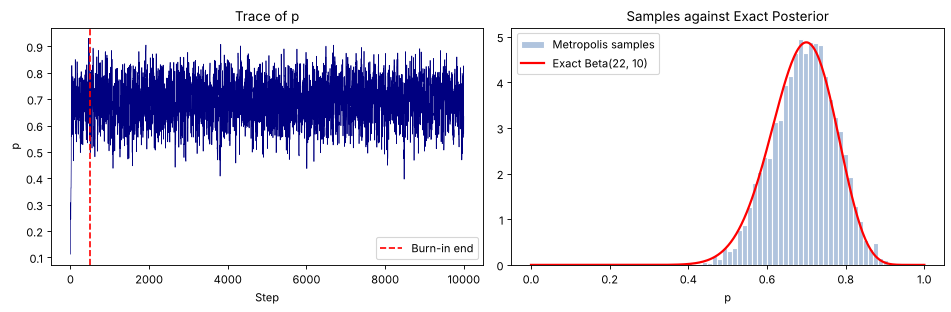

In [3]:
burn = 500
kept = samples[burn:]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(samples, color="navy", linewidth=0.6)
axes[0].axvline(burn, color="red", linestyle="--", label="Burn-in end")
axes[0].set_title("Trace of p")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("p")
axes[0].legend()
grid = np.linspace(0, 1, 300)
axes[1].hist(kept, bins=40, density=True, color="lightsteelblue", edgecolor="white", label="Metropolis samples")
axes[1].plot(grid, stats.beta.pdf(grid, heads + 1, flips - heads + 1), color="red", linewidth=2, label="Exact Beta(22, 10)")
axes[1].set_title("Samples against Exact Posterior")
axes[1].set_xlabel("p")
axes[1].legend()
plt.tight_layout()
plt.show()
exact_mean = (heads + 1) / (flips + 2)
exact_std = stats.beta.std(heads + 1, flips - heads + 1)
print("Sampled mean:", round(kept.mean(), 4), " Exact mean:", round(exact_mean, 4))
print("Sampled std :", round(kept.std(), 4), " Exact std :", round(exact_std, 4))

**Result:** After dropping 500 burn-in steps the sampled mean is 0.6933 against the exact mean 0.6875, and the sampled standard deviation is 0.0798 against 0.0807. The histogram follows the exact curve, so the algorithm works.

### Effect of the step size

In [4]:
rows = []
for width in [0.01, 0.1, 0.5, 3.0]:
    s, r = metropolis(start=0.1, steps=10000, width=width)
    rows.append([width, round(r, 3), round(s[burn:].mean(), 4)])
step_table = pd.DataFrame(rows, columns=["Step width", "Acceptance rate", "Sampled mean"])
print(step_table.to_string(index=False))
print("Exact mean:", round(exact_mean, 4))

 Step width  Acceptance rate  Sampled mean
       0.01            0.957        0.7141
       0.10            0.635        0.6933
       0.50            0.194        0.6849
       3.00            0.033        0.6804
Exact mean: 0.6875


**Result:** A very small step width gives a high acceptance rate but the chain moves slowly, and a very large step width gives a low acceptance rate because most proposals are rejected. A moderate step width such as 0.1 to 0.5 gives a good balance.

## Part B: Deterministic Model

A deterministic model has no random part: the same input always gives the same output. The sunspot cycle is modelled by a fixed equation

**count(t) = A x sin^2( pi x (t - t0) / P )**

where A is the peak height, P is the cycle length in years and t0 is the starting year. The values of A, P and t0 are found by least squares.

In [5]:
sun = pd.read_csv("../Datasets/../Datasets/sunspots.csv")
date_col = [c for c in sun.columns if "date" in c.lower()][0]
sun["date"] = pd.to_datetime(sun[date_col])
sun["count"] = sun.iloc[:, -2 if sun.columns[-1] == "date" else -1].astype(float)
years = (sun["date"].dt.year + (sun["date"].dt.month - 0.5) / 12).to_numpy()
y = sun["count"].to_numpy()

def cycle_model(t, amp, period, t0):
    return amp * np.sin(np.pi * (t - t0) / period) ** 2

best_sse, start = np.inf, None
for period in np.arange(10, 12.6, 0.1):
    for t0 in np.arange(0, period, 0.5):
        sse = ((y - cycle_model(years, y.mean() * 1.8, period, t0)) ** 2).sum()
        if sse < best_sse:
            best_sse, start = sse, [y.mean() * 1.8, period, t0]

params, _ = optimize.curve_fit(cycle_model, years, y, p0=start, maxfev=20000)
amp, period, t0 = params
fitted = cycle_model(years, *params)
rmse = np.sqrt(((y - fitted) ** 2).mean())
r2 = 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print("Peak height A :", round(amp, 2))
print("Cycle length P:", round(period, 3), "years")
print("Start offset  :", round(t0, 3))
print("RMSE          :", round(rmse, 2))
print("R-squared     :", round(r2, 3))

Peak height A : 138.19
Cycle length P: 10.883 years
Start offset  : 7.653
RMSE          : 47.42
R-squared     : 0.434


**Result:** The fitted deterministic model has peak height A = 138.19 and cycle length P = 10.883 years. It explains R-squared = 0.434 of the variation, with an RMSE of 47.42 sunspots.

Mean residual: 4.55


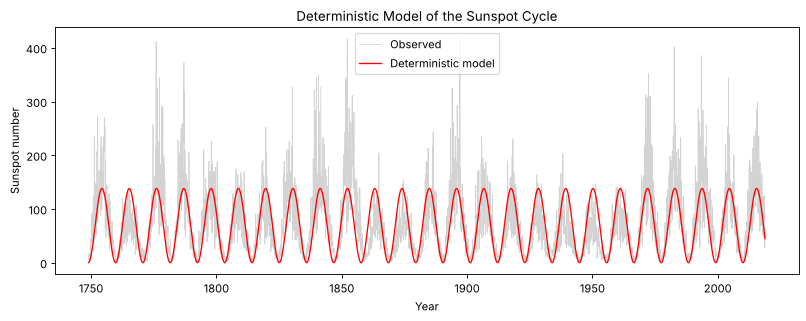

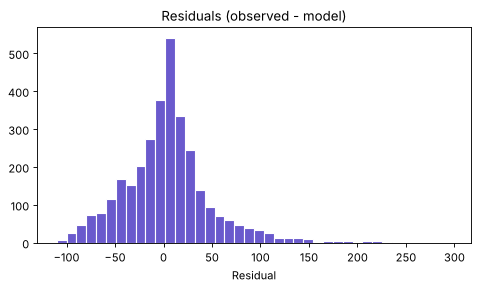

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(years, y, color="lightgray", linewidth=0.7, label="Observed")
plt.plot(years, fitted, color="red", linewidth=1.2, label="Deterministic model")
plt.title("Deterministic Model of the Sunspot Cycle")
plt.xlabel("Year")
plt.ylabel("Sunspot number")
plt.legend()
plt.show()
residual = y - fitted
plt.figure(figsize=(7, 3.5))
plt.hist(residual, bins=40, color="slateblue", edgecolor="white")
plt.title("Residuals (observed - model)")
plt.xlabel("Residual")
plt.show()
print("Mean residual:", round(residual.mean(), 2))

**Result:** The red curve follows the repeating cycles of the observed data but cannot reproduce the changes in height from one cycle to the next, because the model uses one fixed peak height. This is why a purely deterministic model leaves residuals, which are centred near 4.55.

In [7]:
future_years = np.arange(years[-1] + 1 / 12, years[-1] + 5 + 1 / 12, 1 / 12)
forecast_one = cycle_model(future_years, *params)
forecast_two = cycle_model(future_years, *params)
same = bool(np.array_equal(forecast_one, forecast_two))
print("Forecast for the next 5 years (every 12th month):")
print(pd.DataFrame({"Year": np.round(future_years[::12], 2), "Predicted count": np.round(forecast_one[::12], 2)}).to_string(index=False))
print("Same input gives same output:", same)

Forecast for the next 5 years (every 12th month):
   Year  Predicted count
2018.96            41.58
2019.96            11.45
2020.96             0.00
2021.96            10.96
2022.96            40.76
Same input gives same output: True


**Result:** The model predicts the sunspot number for the next five years from the fitted equation. Running the forecast twice gives identical values (check: True), which shows the model is deterministic.